# Does the adversary break updated decompositions by unbalancing changes that cancel? (E17)

*2026-10-21. Record and full tables: `reports/2026-10-21_analysis_cancellation.md`. Plan: `reports/2026-10-21_plan_cancellation.md`. Words as in `GOALS.md` → Terms.*

## The answer

No. We asked whether VPD's adversarial check fails on updated models because the maps write the update as many opposing changes that only add up together. They do not. Component training's changes add up coherently on all six tasks, in the weights and in the output. The least-squares split's cancel only mildly. Removing exactly the part of the changes that the adversary removes explains under a tenth of its extra damage, no more than a shuffled pattern. The rest must come from what the adversary does to the original subcomponents. That last step is inferred, not yet measured; a follow-up that measures it is being built.

*Note 2026-10-21, after E20: measured directly, this inference is refuted. The original subcomponents carry none of the excess on three of the four failing states and a fifth on r2 t275; most of it sits in the adversary's mask on the dead subcomponents and Δ. See `notebooks/E20_cancellation_complement.ipynb`.*

## The question

VPD checks a decomposition by masking subcomponents and measuring how far the output moves, as a KL divergence from the unmasked model. Three of its checks mask gently: at random, at the importance values, or not at all. The fourth is an adversary. Within the range the importance values allow, it picks the mask that hurts the output most. Every map we have tried that keeps a fine-tune's behaviour inside the subcomponents passes the gentle checks and fails the adversarial one.

One candidate reason is cancellation. A map writes the update as one change per subcomponent. If those changes are large and point against each other, their sum can be small while any subset of them is far from it. Mask a few subcomponents and a large uncancelled leftover appears.

Two earlier readings made this plausible. Turning every maskable subcomponent down together costs about a fiftieth of what the adversary's chosen mask costs. A uniform turn-down keeps opposing changes in balance, while a selective mask breaks it. And the subcomponents the adversary turns down are harmless one at a time, at both the original and the updated model, yet harmful together. That is a joint effect, which is what cancellation produces.

The answer decides where to look next. If the changes cancel, the fix is to constrain how a map places the update. If they do not, the problem lies in what the adversary does to the rest of the decomposition.

## What we did

We took nine updated models, each with its decomposition, rebuilt from the saved files of earlier runs. We call each one a state. Every state was read on the first 128 rows of Pile validation text, the same rows as the original model.

- **Component training** at step 10 on six tasks, the emoticon task and five next-word tasks. Three of the six pass the adversarial check and three fail it.
- **The least-squares split** of the emoticon fine-tune, which fails the check.
- **The adjoint split** of the same fine-tune, which passes. Its changes are aligned by construction, so it is the reference for changes that do not cancel.
- **A positive control** built to cancel. We took component training's emoticon changes and mixed the subcomponents among each other. The write vectors were multiplied by an invertible matrix, the read vectors by its inverse transpose. The total weight change stays exactly the same, while each subcomponent's change gains parts that others lose. The mixing was scaled until the changes' total size was 64 times the original. This state should read as cancelling on every test.

Four symbols carry the rest of the notebook:

- $d_c = u'_c v'^\top_c - u_c v_c^\top$ is subcomponent $c$'s change: its rank-one weight after the update minus before.
- $\kappa$ is the coherence of the changes in the weights, defined in test 1.
- $h$ is the half-revert ratio, defined in test 1.
- $X$ is the adversary's extra damage: its KL at the state minus its KL at the original model, on the same rows.

Before any reading, two checks ran on every state and passed. The hook that removes changes reproduces the edited weights to within a billionth of a nat. The coherence's null reads 1 within 0.1.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / 'experiments').is_dir() else Path.cwd().parent
EXP = ROOT / 'experiments/cancellation'
out = json.loads((EXP / 'results/cancellation.json').read_text())
st, w0 = out['states'], out['W0']['pgd_kl']
assert all(out['score']['G1_hook_identity'].values()) and all(out['score']['G2_coherence_null'].values())
NAMES = {'adjoint emoticon': 'adjoint split, emoticon', 'ct emoticon': 'component training, emoticon',
         'ct r1_t588_v452': 'component training, r1 t588', 'ct r2_t359_v816': 'component training, r2 t359',
         'ct r0_t352_v310': 'component training, r0 t352', 'ct r1_t534_v369': 'component training, r1 t534',
         'ct r2_t275_v2667': 'component training, r2 t275', 'ls emoticon': 'least-squares split, emoticon',
         'c1 emoticon': 'control, mixed changes'}
print(f'{len(st)} states; the original model under the adversary: {w0:.3f} nats')

9 states; the original model under the adversary: 0.661 nats


## What we expected

- **Coherence.** We expected the changes to add, not cancel, even on the failing states. Adam's steps are sign-like, and ten steps on a narrow task move the weights in few directions. We filed the cancellation hypothesis's weight-space claim as likely to fail.
- **The half revert.** We expected it above 1 on the failing states and at most 0.5 on the adjoint split, with low confidence. The reason was the selective-mask reading above.
- **The adversary's revert.** We expected the adversary's part of the changes to carry at least half of its extra damage. We also expected three times what a shuffled pattern carries.
- **The control** should read as cancelling on both coherence and the half revert.

## 1. Do the changes cancel, in the weights or in their effect?

There are two ways to ask. **In the weights**, the coherence is $\kappa = \|\sum_c d_c\|^2 / \sum_c \|d_c\|^2$, pooled over matrices. Unrelated changes read about 1, because their cross terms average out. Changes pointing the same way read more than 1. Cancelling changes read below 1, since their sum is shorter than its parts. A null flips the sign of each change at random and should read 1.

**In effect**, we ask the model. A forward hook removes the changes of a random half of the subcomponents and leaves the original subcomponents whole. We measure the KL between the state and this half-reverted state, and divide it by the KL of removing every change. That ratio is $h$, averaged over three random halves.

The drawing below shows what $h$ should read. For a small change, the KL grows with the square of how far the output moves. So picture each change's effect on the output as an arrow, and the update as their sum.

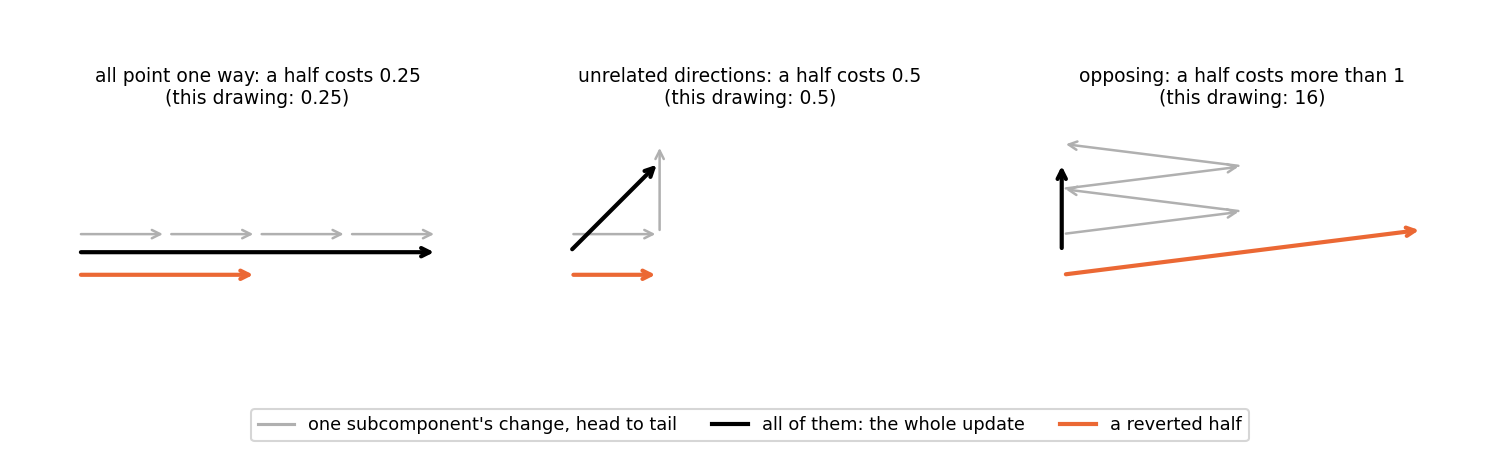

In [2]:
display(Image(EXP / 'figures/half_revert_toy.png'))

If every change points one way, a half moves the output half as far, which costs a quarter. If the changes point in unrelated directions, a half carries half the squared length, which costs a half. If the changes oppose each other and their sum is short, a half leaves a long uncancelled arrow, which costs more than the whole. In a formula, a random half costs about $\tfrac14(1 + 1/c)$ of the whole, where $c$ is the coherence of the arrows. If the changes' effects line up the way their weights do, then $c = \kappa$, and $h$ should fall on the curve $\tfrac14(1 + 1/\kappa)$. That curve is the dashed line in the next figure.

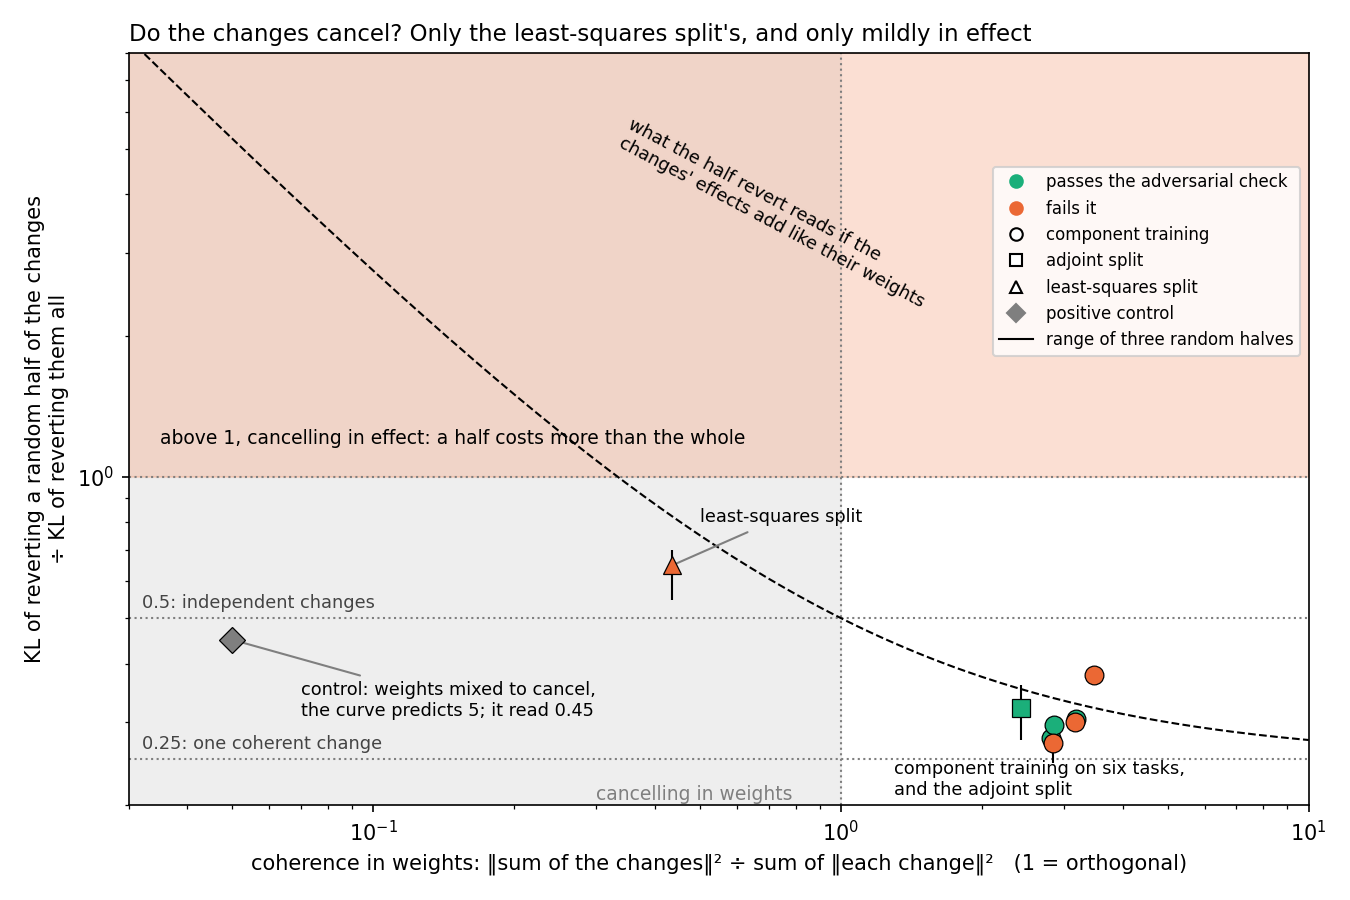

In [3]:
display(Image(EXP / 'figures/half_revert.png'))

**Reading it.** The changes add up; only the least-squares split's cancel, and in effect only mildly. Component training sits at a coherence of about 3 on all six tasks, passing and failing alike, while the sign-flip null reads 1. Its half revert reads 0.27 to 0.38, on the dashed curve, between one coherent change and independent changes. So its changes' effects line up the way their weights do, and the adjoint split sits with them. The least-squares split is the only map whose changes cancel in the weights, at 0.44. In effect it reads 0.65: above independent changes, but well below the line at 1 where a half costs the whole. Nothing in this figure separates the states that fail the adversarial check from those that pass.

## 2. Why the control failed, and what that costs

The control is the grey diamond. Its weight coherence is 0.05, so if its effects followed its weights, the half revert would read about 5. It read 0.45. The parts the mixing added are large in the weights but move the output little on this text, and roughly in unrelated directions. The control injected cancellation that the model does not feel, and its filed rule required a half revert above 1, so it failed.

**What this undermines.** The half revert has no demonstrated case of catching cancellation, so the filed predictions are unscored and the numbers here are readings. Read against the dashed curve, though, the control is not evidence that the half revert is blind. Its point is where the curve says it should be if the mixed parts barely reach the output.

**What it does not undermine.** The control cannot rescue the cancellation hypothesis. Test 3 below does not use the half revert. It reads the adversary's own mask directly, and its only apparatus is the hook, which reproduced the weight edit exactly.

## 3. Does removing the changes explain the adversary's extra damage?

The adversary's mask keeps each subcomponent at least at its importance value and chooses a level between that and full. At an input $x$ it keeps $g_c(x) + (1 - g_c(x))\,a_c$ of subcomponent $c$, where $g_c$ is the importance and $a_c$ in $[0, 1]$ is the adversary's choice. So it removes the fraction $(1 - g_c(x))(1 - a_c)$ of the subcomponent, and that includes the same fraction of its change. The hook can remove exactly that fraction of each change alone, leaving the original subcomponents whole. If the adversary's damage were the uncancelled leftover of the changes, this revert would carry most of $X$. The filed bar was at least half, and three times a null that shuffles the adversary's choices among the subcomponents of each matrix.

In the figure, each state's extra damage $X$ is a bar of height 1, with its size in nats above it. The coloured part is what removing the changes alone costs. The hatched rest is what this run did not measure.

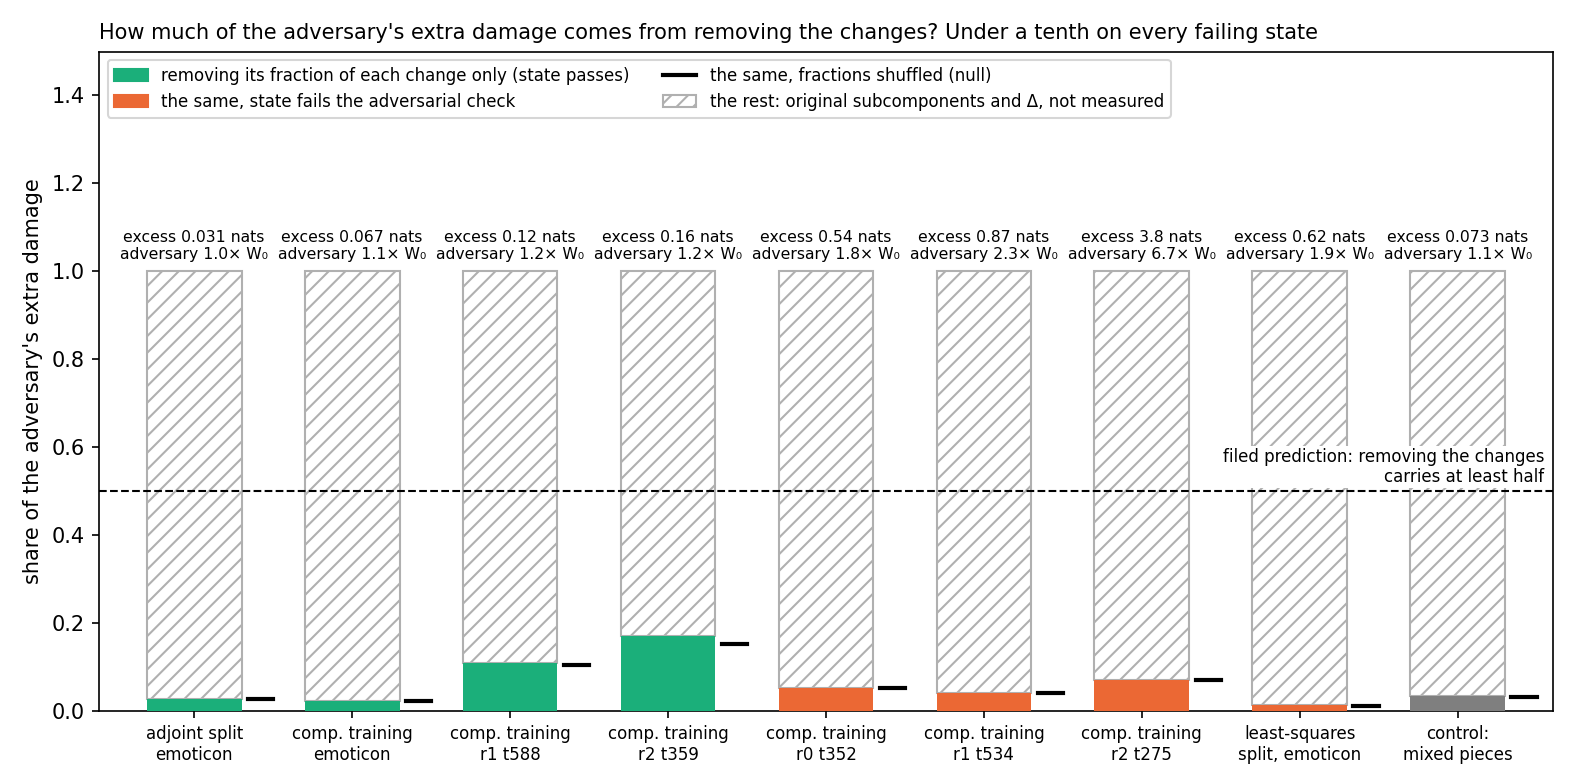

In [4]:
display(Image(EXP / 'figures/adversary_revert.png'))

**Reading it.** No. On every failing state, removing just the changes carries under a tenth of the adversary's extra damage. That is a few percent for component training and one percent for the least-squares split. Shuffling which subcomponent gets which fraction costs the same, within a fifth on every state. The original model's own adversary, applied to the changes, costs the same again. So the adversary is not singling out the changes: any pattern of its size removes about as much. The passing states show the same picture with a smaller $X$.

In [5]:
rows = ['| state | adversary ÷ original model | extra damage, nats | share from removing the changes | shuffled |',
        '|---|---|---|---|---|']
for k, name in NAMES.items():
    r = st[k]
    x = r['pgd_kl'] - w0
    rows.append(f"| {name} | {r['pgd_kl'] / w0:.2f} | {x:.3f} | {r['F_adv'] / x:.1%} | {sum(r['F_perm']) / 3 / x:.1%} |")
display(Markdown('\n'.join(rows)))

| state | adversary ÷ original model | extra damage, nats | share from removing the changes | shuffled |
|---|---|---|---|---|
| adjoint split, emoticon | 1.05 | 0.031 | 2.5% | 2.6% |
| component training, emoticon | 1.10 | 0.067 | 2.2% | 2.2% |
| component training, r1 t588 | 1.18 | 0.121 | 10.8% | 10.3% |
| component training, r2 t359 | 1.24 | 0.156 | 17.0% | 15.1% |
| component training, r0 t352 | 1.82 | 0.540 | 5.1% | 5.2% |
| component training, r1 t534 | 2.31 | 0.867 | 4.0% | 3.9% |
| component training, r2 t275 | 6.72 | 3.785 | 6.9% | 6.9% |
| least-squares split, emoticon | 1.93 | 0.616 | 1.3% | 1.1% |
| control, mixed changes | 1.11 | 0.073 | 3.3% | 3.2% |

## 4. What that leaves

The hatched part of each bar is the adversary's mask acting on the original subcomponents and on Δ, the weights outside the subcomponents. It also holds how those removals interact with the changes. This run did not measure it. It is the extra damage minus what was measured, and KL does not add exactly, so it is an estimate.

Our reading is that after the update, the output leans more on original subcomponents that Γ rates unimportant on Pile text. The adversary is free to remove those. That is an inference from the remainder, not a measurement. A follow-up in the same hook framework is being built. It removes the adversary's fractions of the original subcomponents while keeping the changes whole. If most of the extra damage appears there, the reading becomes a measurement. If little does, the damage lies in how the two halves interact.

*Note 2026-10-21, after E20: measured directly, this inference is refuted. The original subcomponents carry none of the excess on three of the four failing states and a fifth on r2 t275; most of it sits in the adversary's mask on the dead subcomponents and Δ. See `notebooks/E20_cancellation_complement.ipynb`.*

## What we learned

Cancellation among the changes is not why the maps fail the adversarial check. Component training writes one coherent change, spread over the subcomponents but adding up, and the adversary gains almost nothing by removing parts of it. The least-squares split's changes cancel in the weights and mildly in effect, and the adversary ignores them too. If the follow-up confirms the remainder, the brittleness question moves back onto Γ in a new form. The problem would not be stale importance values on the changed subcomponents. An earlier test ruled that out one at a time, and this run rules it out together. It would be a stale allowed range around the original subcomponents, which the updated model now uses. The research log's claim that the failure is cancellation is refuted.

## How compelling is the evidence

Nine states on six tasks, each read on the same 128 rows as the original model, with every number beside its null. There is one update seed per state and one adversary seed. The hook reproduced the edited weights to a billionth of a nat on every state. The adversary's ratios on these rows reproduce the earlier runs' ordering of passing and failing states. The coherence null reads 0.96 to 1.02 everywhere.

The positive control failed, so the half revert's readings are unscored. Test 3 does not depend on that control. Blind spots: everything reads Pile text, never the trigger. The weight coherence is blind to the output. Random halves are blind to one specific cancelling subset, which test 3 covers. The hook keeps the original subcomponents whole, so their share of the damage is inferred, not measured.

## Surprises

**Two filed predictions reversed.** The half revert was predicted above 1 on the failing states. It read about 0.3 for component training and 0.65 for the least-squares split. The adversary's revert was predicted to carry at least half of its extra damage; it carried a few percent and matched the shuffled null. The explanation in section 4 is a reading of the remainder, and the follow-up measures it.

Smaller ones. The least-squares split's weight coherence read 0.44, where the plan expected above 1. The control's 64-fold mixing barely moved the half revert, so cancellation in the weights and cancellation in the output come apart. The first smoke run failed its own hook check because the check's reference ran with the hook live; the check worked as designed.

## What next

- **Measure the remainder**, now being built: remove the adversary's fractions of the original subcomponents while keeping the changes whole. Most of the extra damage there confirms the reading in section 4; little there points at the interaction.
- **Which original subcomponents**: bin the adversary's mask by layer and by importance at the state and at the original model. This asks which low-importance subcomponents the updated model leans on.
- **E18, mechanism or leak**, as planned, with a sharper question: are the subcomponents the adversary removes the ones Γ switches on at the trigger?

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| G1 | the hook reproduces the weight edit | KL 0 at weight 0; ≤ 1e-4 at weight 1 | 0 and about 1e-9 everywhere | pass |
| G2 | the coherence null reads 1 | within 0.1 | 0.96 to 1.02 | pass |
| C1 | the mixed changes read as cancelling | κ ≤ κ_ct ÷ 5 and h > 1 | κ ratio 0.016; h 0.45 | fail (h): P1 to P3 unscored |
| P1 | coherence below 1 on the scored states | κ < 1 | 3.16, 2.84, 3.48; least-squares 0.44 | unscored; reads fail, as predicted |
| P2 | half revert above 1; adjoint ≤ 0.5 | h > 1; h ≤ 0.5 | 0.30, 0.27, 0.38, 0.65; adjoint 0.32 | unscored; reads fail, predicted pass |
| P3 | the adversary removes the cancelling part | F_adv ≥ 3 F_perm and ≥ 0.5 X | 0.98 to 1.20 × F_perm; 0.01 to 0.07 X | unscored; reads fail, predicted pass |

## Not run

- The complement revert: the adversary's fractions of the original subcomponents with the changes kept. Being built.
- The ladder tasks' split states; a second update seed; a second adversary seed.
- A positive control that cancels in the output, not only in the weights.
- The revert restricted to low-importance subcomponents; the trigger windows.

## Provenance

`experiments/cancellation/results/cancellation.json`, sha256 `3e54f538…`. MATS cluster L40, 2026-10-21, $0: CPU smoke job 28107, scored job 28110 in 557 s. Code `src/commute/cancel.py` and `experiments/cancellation/run.py`; figures by `experiments/cancellation/plot.py`.